<a href="https://www.kaggle.com/code/mdemonbinabutaher/reinal-oct-image-classification?scriptVersionId=373978979" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

# **Libraries**

In [1]:
import os
import gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    roc_auc_score
)

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.20.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


# **Kaggle GPU Check** 

In [2]:
import tensorflow as tf
import subprocess

print("=" * 60)
print("TensorFlow GPU CHECK")
print("=" * 60)

print("TensorFlow version:", tf.__version__)

gpus = tf.config.list_physical_devices("GPU")

print("\nAvailable GPUs:")
for gpu in gpus:
    print(gpu)

print("\nNumber of GPUs:", len(gpus))

if len(gpus) > 0:
    print("\n✅ GPU is available!")

    strategy = tf.distribute.MirroredStrategy()

    print("Number of replicas:",
          strategy.num_replicas_in_sync)

else:
    print("\n❌ GPU is NOT detected by TensorFlow")

print("\n" + "=" * 60)
print("NVIDIA-SMI")
print("=" * 60)

subprocess.run(["nvidia-smi"])

TensorFlow GPU CHECK
TensorFlow version: 2.20.0

Available GPUs:
PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')
PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')

Number of GPUs: 2

✅ GPU is available!
INFO:tensorflow:Using MirroredStrategy with devices ('/job:localhost/replica:0/task:0/device:GPU:0', '/job:localhost/replica:0/task:0/device:GPU:1')
Number of replicas: 2

NVIDIA-SMI
Wed Nov 25 13:53:15 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. 

I0000 00:00:1795614795.188405      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1795614795.192957      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


CompletedProcess(args=['nvidia-smi'], returncode=0)

# **Dataset Path**

In [3]:
TRAIN_DIR = "/kaggle/input/datasets/obulisainaren/retinal-oct-c8/RetinalOCT_Dataset/RetinalOCT_Dataset/train"
VAL_DIR   = "/kaggle/input/datasets/obulisainaren/retinal-oct-c8/RetinalOCT_Dataset/RetinalOCT_Dataset/val"
TEST_DIR  = "/kaggle/input/datasets/obulisainaren/retinal-oct-c8/RetinalOCT_Dataset/RetinalOCT_Dataset/test"

CLASS_NAMES = ['DR', 'AMD', 'CSR', 'DRUSEN', 'CNV', 'NORMAL', 'MH', 'DME']

print(os.listdir(TRAIN_DIR))
print(os.listdir(VAL_DIR))
print(os.listdir(TEST_DIR))

['AMD', 'CNV', 'CSR', 'DME', 'DR', 'DRUSEN', 'MH', 'NORMAL']
['AMD', 'CNV', 'CSR', 'DME', 'DR', 'DRUSEN', 'MH', 'NORMAL']
['AMD', 'CNV', 'CSR', 'DME', 'DR', 'DRUSEN', 'MH', 'NORMAL']


# **Dataset Count Check**

In [4]:
def count_images(directory):
    result = {}

    for cls in CLASS_NAMES:
        class_path = os.path.join(directory, cls)

        if os.path.exists(class_path):
            files = [
                f for f in os.listdir(class_path)
                if f.lower().endswith(
                    (".jpg", ".jpeg", ".png", ".bmp", ".webp")
                )
            ]

            result[cls] = len(files)
        else:
            result[cls] = 0

    return result


train_counts = count_images(TRAIN_DIR)
val_counts   = count_images(VAL_DIR)
test_counts  = count_images(TEST_DIR)

print("Train:", train_counts)
print("Validation:", val_counts)
print("Test:", test_counts)

Train: {'DR': 2300, 'AMD': 2300, 'CSR': 2300, 'DRUSEN': 2300, 'CNV': 2300, 'NORMAL': 2300, 'MH': 2300, 'DME': 2300}
Validation: {'DR': 350, 'AMD': 350, 'CSR': 350, 'DRUSEN': 350, 'CNV': 350, 'NORMAL': 350, 'MH': 350, 'DME': 350}
Test: {'DR': 350, 'AMD': 350, 'CSR': 350, 'DRUSEN': 350, 'CNV': 350, 'NORMAL': 350, 'MH': 350, 'DME': 350}


# **Class Distribution Visualization**

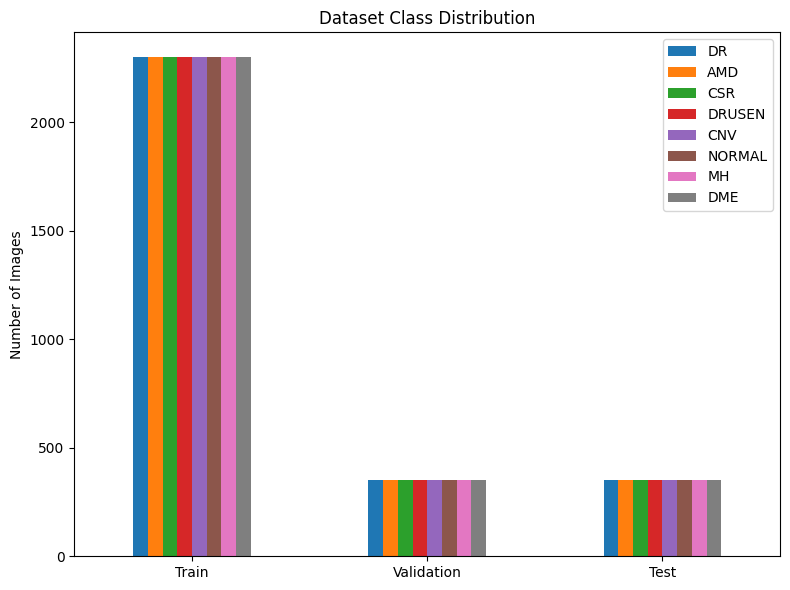

In [5]:
# Create DataFrame
df_distribution = pd.DataFrame({
    "DR":     [train_counts["DR"],     val_counts["DR"],     test_counts["DR"]],
    "AMD":    [train_counts["AMD"],    val_counts["AMD"],    test_counts["AMD"]],
    "CSR":    [train_counts["CSR"],    val_counts["CSR"],    test_counts["CSR"]],
    "DRUSEN": [train_counts["DRUSEN"], val_counts["DRUSEN"], test_counts["DRUSEN"]],
    "CNV":    [train_counts["CNV"],    val_counts["CNV"],    test_counts["CNV"]],
    "NORMAL": [train_counts["NORMAL"], val_counts["NORMAL"], test_counts["NORMAL"]],
    "MH":     [train_counts["MH"],     val_counts["MH"],     test_counts["MH"]],
    "DME":    [train_counts["DME"],    val_counts["DME"],    test_counts["DME"]]
}, index=["Train", "Validation", "Test"])

# Plot
df_distribution.plot(kind="bar", figsize=(8,6))
plt.title("Dataset Class Distribution")
plt.ylabel("Number of Images")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# **Image Size**

In [6]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42
EPOCHS = 5

# **Data Generator**

In [7]:
train_datagen = tf.keras.preprocessing.image.ImageDataGenerator(
    rotation_range=15,
    width_shift_range=0.10,
    height_shift_range=0.10,
    zoom_range=0.10,
    horizontal_flip=True
)

val_datagen = tf.keras.preprocessing.image.ImageDataGenerator()

test_datagen = tf.keras.preprocessing.image.ImageDataGenerator()

# **Train Generator**

In [8]:
train_generator = train_datagen.flow_from_directory(
    TRAIN_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    classes=CLASS_NAMES,
    shuffle=True,
    seed=SEED
)

Found 18400 images belonging to 8 classes.


# **Validation Generator**

In [9]:
val_generator = val_datagen.flow_from_directory(
    VAL_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    classes=CLASS_NAMES,
    shuffle=False
)

Found 2800 images belonging to 8 classes.


# **Test Generator**

In [10]:
test_generator = test_datagen.flow_from_directory(
    TEST_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    classes=CLASS_NAMES,
    shuffle=False
)

print(test_generator.class_indices)

Found 2800 images belonging to 8 classes.
{'DR': 0, 'AMD': 1, 'CSR': 2, 'DRUSEN': 3, 'CNV': 4, 'NORMAL': 5, 'MH': 6, 'DME': 7}


# **Sample Image Visualization**

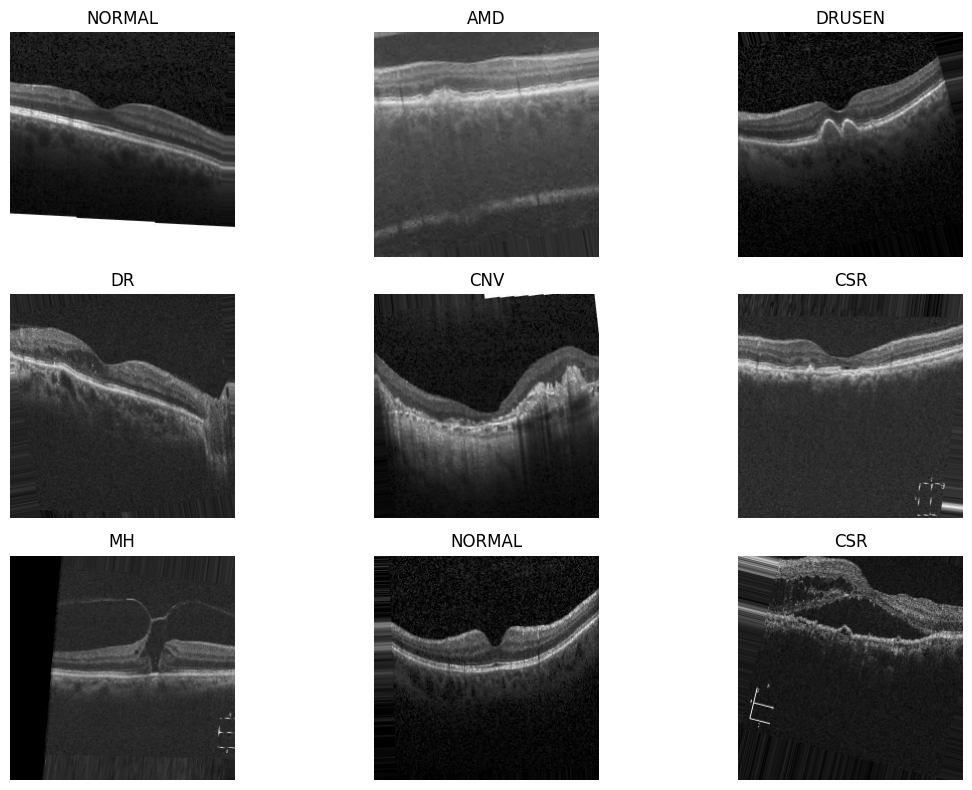

In [11]:
images, labels = next(train_generator)

plt.figure(figsize=(12, 8))

for i in range(9):
    plt.subplot(3, 3, i + 1)

    plt.imshow(images[i].astype("uint8"))

    # One-hot encoded label → class index
    label_index = np.argmax(labels[i])

    label = CLASS_NAMES[label_index]

    plt.title(label)
    plt.axis("off")

plt.tight_layout()
plt.show()

# **Models Define**

1. Xception
2. ResNet50
3. MobileNetV3Large
4. EfficientNetB7
5. DenseNet121
6. InceptionV3

Keras Applications-এ pretrained ImageNet models feature extraction and fine-tuning

In [12]:
from tensorflow.keras.applications import (
    Xception,
    ResNet50,
    MobileNetV3Large,
    EfficientNetB7,
    DenseNet121,
    InceptionV3
)

# **Model Configuration**

In [13]:
MODEL_CONFIGS = {

    "Xception": {
        "model": Xception,
        "input_size": (224, 224)
    },

    "ResNet50": {
        "model": ResNet50,
        "input_size": (224, 224)
    },

    "MobileNetV3Large": {
        "model": MobileNetV3Large,
        "input_size": (224, 224)
    },

    "EfficientNetB7": {
        "model": EfficientNetB7,
        "input_size": (224, 224)
    },

    "DenseNet121": {
        "model": DenseNet121,
        "input_size": (224, 224)
    },

    "InceptionV3": {
        "model": InceptionV3,
        "input_size": (224, 224)
    }
}

# **Transfer Learning Model Function**

In [14]:
def build_transfer_model(base_model_class, input_shape=(224, 224, 3)):

    base_model = base_model_class(
        weights="imagenet",
        include_top=False,
        input_shape=input_shape
    )

    # Freeze pretrained layers
    base_model.trainable = False

    inputs = keras.Input(shape=input_shape)

    x = base_model(inputs, training=False)

    x = layers.GlobalAveragePooling2D()(x)

    x = layers.BatchNormalization()(x)

    x = layers.Dropout(0.4)(x)

    x = layers.Dense(
        256,
        activation="relu"
    )(x)

    x = layers.Dropout(0.3)(x)

    outputs = layers.Dense(
        8,
        activation="softmax"
    )(x)

    model = keras.Model(
        inputs,
        outputs
    )

    model.compile(
        optimizer=keras.optimizers.Adamax(
            learning_rate=1e-4
        ),
        loss="categorical_crossentropy",
        metrics=[
            "accuracy"
        ]
    )

    return model

# **Callbacks**

In [15]:
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint
)

In [16]:
def get_callbacks(model_name):

    os.makedirs("models", exist_ok=True)

    return [

        EarlyStopping(
            monitor="val_loss",
            patience=5,
            restore_best_weights=True,
            verbose=1
        ),

        ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.2,
            patience=2,
            min_lr=1e-7,
            verbose=1
        ),

        ModelCheckpoint(
            filepath=f"models/{model_name}_best.keras",
            monitor="val_accuracy",
            #save_best_only=True,
            verbose=1
        )
        
    ]

# **One Model Train Function**

In [17]:
def train_model(model_name, model_class):

    print("=" * 70)
    print(f"Training: {model_name}")
    print("=" * 70)

    model = build_transfer_model(
        model_class,
        input_shape=(*IMG_SIZE, 3)
    )

    history = model.fit(
        train_generator,
        validation_data=val_generator,
        epochs=EPOCHS,
        callbacks=get_callbacks(model_name)
    )

    return model, history

# **Accuracy & Loss Visualization**

In [18]:
def plot_training_history(history, model_name):

    plt.figure(figsize=(14, 5))

    plt.subplot(1, 2, 1)

    plt.plot(
        history.history["accuracy"],
        label="Train Accuracy"
    )

    plt.plot(
        history.history["val_accuracy"],
        label="Validation Accuracy"
    )

    plt.title(f"{model_name} Accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend()

    plt.subplot(1, 2, 2)

    plt.plot(
        history.history["loss"],
        label="Train Loss"
    )

    plt.plot(
        history.history["val_loss"],
        label="Validation Loss"
    )

    plt.title(f"{model_name} Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()

    plt.tight_layout()
    plt.show()

# **Total Model Train**

In [19]:
models = {}
histories = {}

Training: Xception
83683744/83683744 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/5


2026-11-25 13:53:43.915737: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-25 13:53:44.097481: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-25 13:53:46.326386: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-25 13:53:46.464900: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-25 13:53:47.727577: E external/local_xla/xla/stream_

575/575 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.2807 - loss: 2.1981

2026-11-25 14:06:51.397235: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-25 14:06:51.552491: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-25 14:06:52.894981: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-25 14:06:53.033287: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-25 14:06:54.046328: E external/local_xla/xla/stream_


Epoch 1: saving model to models/Xception_best.keras

Epoch 1: finished saving model to models/Xception_best.keras
575/575 ━━━━━━━━━━━━━━━━━━━━ 813s 1s/step - accuracy: 0.3331 - loss: 1.9313 - val_accuracy: 0.4346 - val_loss: 1.3762 - learning_rate: 1.0000e-04
Epoch 2/5
575/575 ━━━━━━━━━━━━━━━━━━━━ 0s 443ms/step - accuracy: 0.3986 - loss: 1.6162
Epoch 2: saving model to models/Xception_best.keras

Epoch 2: finished saving model to models/Xception_best.keras
575/575 ━━━━━━━━━━━━━━━━━━━━ 268s 465ms/step - accuracy: 0.4095 - loss: 1.5710 - val_accuracy: 0.4668 - val_loss: 1.2844 - learning_rate: 1.0000e-04
Epoch 3/5
575/575 ━━━━━━━━━━━━━━━━━━━━ 0s 444ms/step - accuracy: 0.4180 - loss: 1.5065
Epoch 3: saving model to models/Xception_best.keras

Epoch 3: finished saving model to models/Xception_best.keras
575/575 ━━━━━━━━━━━━━━━━━━━━ 268s 466ms/step - accuracy: 0.4278 - loss: 1.4637 - val_accuracy: 0.4918 - val_loss: 1.1924 - learning_rate: 1.0000e-04
Epoch 4/5
575/575 ━━━━━━━━━━━━━━━━━━━━ 

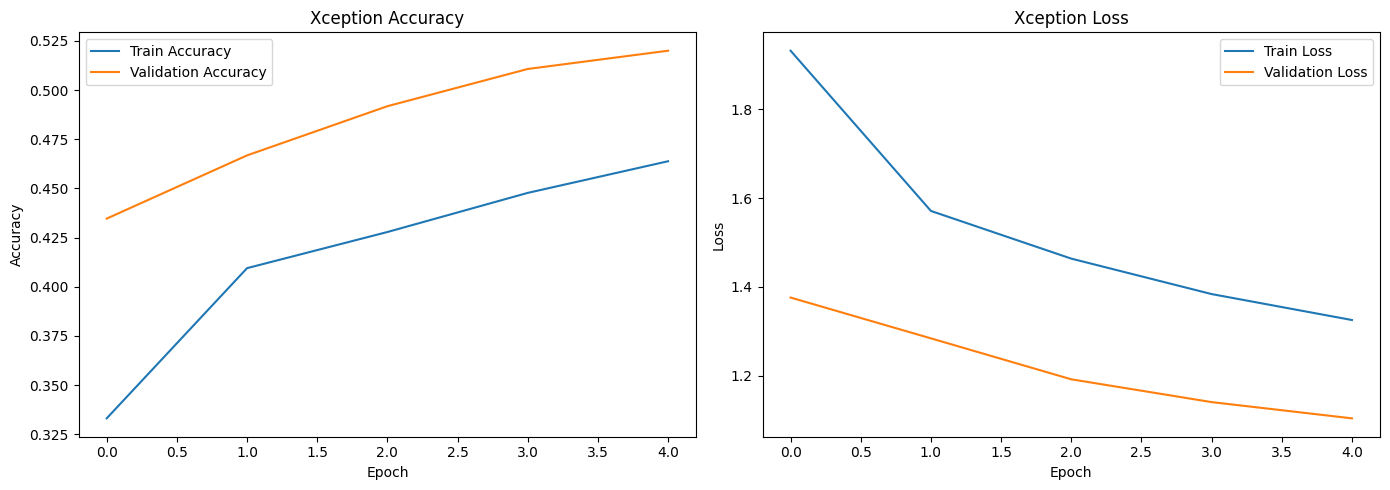

Training: ResNet50
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/5
575/575 ━━━━━━━━━━━━━━━━━━━━ 0s 424ms/step - accuracy: 0.3726 - loss: 2.0448
Epoch 1: saving model to models/ResNet50_best.keras

Epoch 1: finished saving model to models/ResNet50_best.keras
575/575 ━━━━━━━━━━━━━━━━━━━━ 278s 460ms/step - accuracy: 0.4858 - loss: 1.5710 - val_accuracy: 0.7593 - val_loss: 0.6711 - learning_rate: 1.0000e-04
Epoch 2/5
575/575 ━━━━━━━━━━━━━━━━━━━━ 0s 431ms/step - accuracy: 0.6421 - loss: 1.0191
Epoch 2: saving model to models/ResNet50_best.keras

Epoch 2: finished saving model to models/ResNet50_best.keras
575/575 ━━━━━━━━━━━━━━━━━━━━ 260s 451ms/step - accuracy: 0.6624 - loss: 0.9616 - val_accuracy: 0.7961 - val_loss: 0.5606 - learning_rate: 1.0000e-04
Epoch 3/5
575/575 ━━━━━━━━━━━━━━━━━━━━ 0s 424ms/step - accuracy: 0.7026 - loss: 0.8178
Epoch 3: saving model to models/ResNet50_best.keras

Epoch 3: finished saving model to models/ResNet50_best.keras
575/575 ━━━━━━━━━━━━━━━━━━━━ 

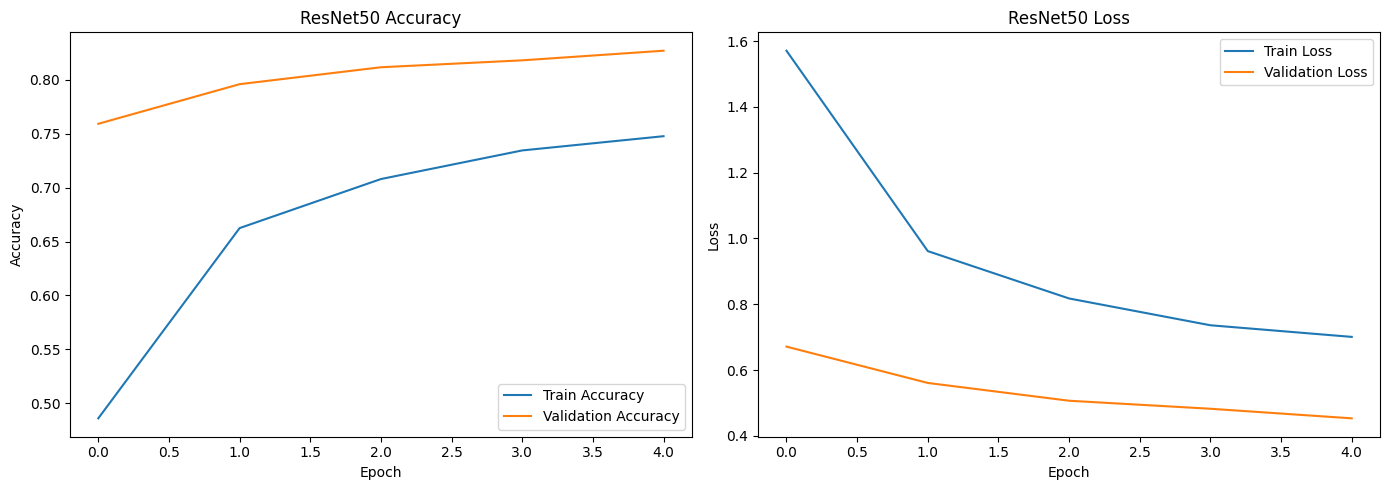

Training: MobileNetV3Large
12683000/12683000 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/5


2026-11-25 14:46:48.612435: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-25 14:46:48.749833: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-25 14:46:49.095490: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-25 14:46:49.232560: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


575/575 ━━━━━━━━━━━━━━━━━━━━ 0s 405ms/step - accuracy: 0.2662 - loss: 2.3363

2026-11-25 14:51:07.871583: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-25 14:51:08.004381: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-25 14:51:08.317895: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-25 14:51:08.455302: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.



Epoch 1: saving model to models/MobileNetV3Large_best.keras

Epoch 1: finished saving model to models/MobileNetV3Large_best.keras
575/575 ━━━━━━━━━━━━━━━━━━━━ 278s 451ms/step - accuracy: 0.3691 - loss: 1.8768 - val_accuracy: 0.6518 - val_loss: 0.9063 - learning_rate: 1.0000e-04
Epoch 2/5
575/575 ━━━━━━━━━━━━━━━━━━━━ 0s 402ms/step - accuracy: 0.5638 - loss: 1.2332
Epoch 2: saving model to models/MobileNetV3Large_best.keras

Epoch 2: finished saving model to models/MobileNetV3Large_best.keras
575/575 ━━━━━━━━━━━━━━━━━━━━ 241s 420ms/step - accuracy: 0.5832 - loss: 1.1653 - val_accuracy: 0.7386 - val_loss: 0.6901 - learning_rate: 1.0000e-04
Epoch 3/5
575/575 ━━━━━━━━━━━━━━━━━━━━ 0s 405ms/step - accuracy: 0.6191 - loss: 1.0382
Epoch 3: saving model to models/MobileNetV3Large_best.keras

Epoch 3: finished saving model to models/MobileNetV3Large_best.keras
575/575 ━━━━━━━━━━━━━━━━━━━━ 244s 424ms/step - accuracy: 0.6412 - loss: 0.9868 - val_accuracy: 0.7725 - val_loss: 0.5919 - learning_rate:

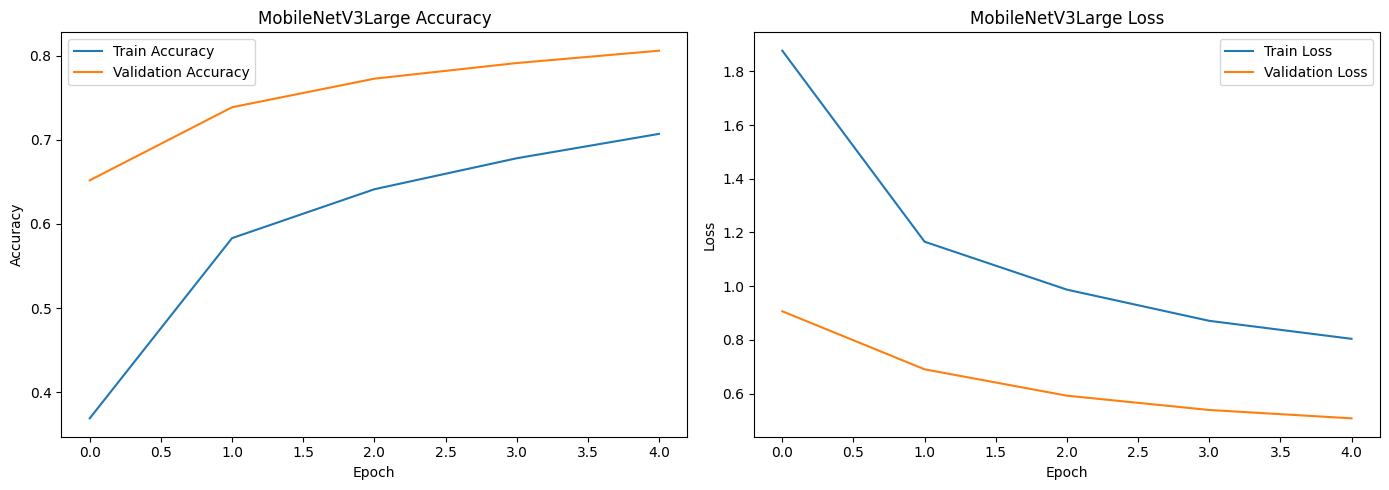

Training: EfficientNetB7
258076736/258076736 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Epoch 1/5


2026-11-25 15:08:33.298900: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-25 15:08:33.442907: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-25 15:08:33.742939: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-25 15:08:33.892844: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-25 15:08:34.322037: E external/local_xla/xla/stream_

575/575 ━━━━━━━━━━━━━━━━━━━━ 0s 457ms/step - accuracy: 0.3448 - loss: 2.1103

2026-11-25 15:14:13.802715: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-25 15:14:13.939221: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-25 15:14:14.193770: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-25 15:14:14.338730: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-25 15:14:14.647010: E external/local_xla/xla/stream_


Epoch 1: saving model to models/EfficientNetB7_best.keras

Epoch 1: finished saving model to models/EfficientNetB7_best.keras
575/575 ━━━━━━━━━━━━━━━━━━━━ 405s 566ms/step - accuracy: 0.4500 - loss: 1.6940 - val_accuracy: 0.7432 - val_loss: 0.7239 - learning_rate: 1.0000e-04
Epoch 2/5
575/575 ━━━━━━━━━━━━━━━━━━━━ 0s 453ms/step - accuracy: 0.6076 - loss: 1.1510
Epoch 2: saving model to models/EfficientNetB7_best.keras

Epoch 2: finished saving model to models/EfficientNetB7_best.keras
575/575 ━━━━━━━━━━━━━━━━━━━━ 287s 498ms/step - accuracy: 0.6266 - loss: 1.0951 - val_accuracy: 0.7954 - val_loss: 0.5697 - learning_rate: 1.0000e-04
Epoch 3/5
575/575 ━━━━━━━━━━━━━━━━━━━━ 0s 464ms/step - accuracy: 0.6711 - loss: 0.9592
Epoch 3: saving model to models/EfficientNetB7_best.keras

Epoch 3: finished saving model to models/EfficientNetB7_best.keras
575/575 ━━━━━━━━━━━━━━━━━━━━ 293s 509ms/step - accuracy: 0.6753 - loss: 0.9389 - val_accuracy: 0.8257 - val_loss: 0.5057 - learning_rate: 1.0000e-04


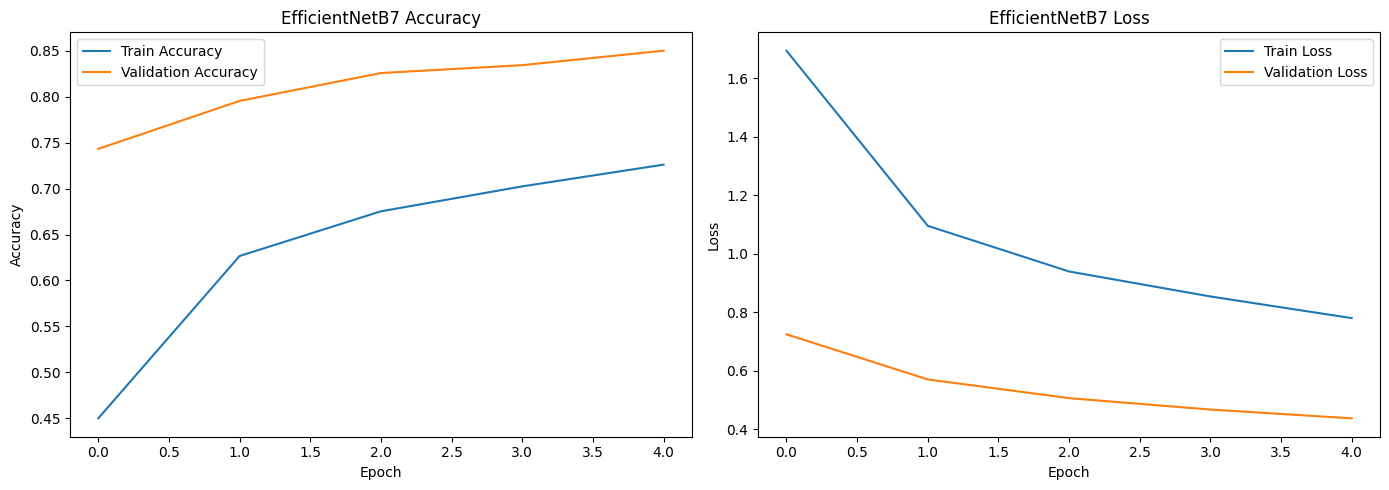

Training: DenseNet121
29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/5
575/575 ━━━━━━━━━━━━━━━━━━━━ 0s 462ms/step - accuracy: 0.3020 - loss: 1.9877
Epoch 1: saving model to models/DenseNet121_best.keras

Epoch 1: finished saving model to models/DenseNet121_best.keras
575/575 ━━━━━━━━━━━━━━━━━━━━ 334s 528ms/step - accuracy: 0.3795 - loss: 1.7081 - val_accuracy: 0.5057 - val_loss: 1.3454 - learning_rate: 1.0000e-04
Epoch 2/5
575/575 ━━━━━━━━━━━━━━━━━━━━ 0s 461ms/step - accuracy: 0.4888 - loss: 1.3350
Epoch 2: saving model to models/DenseNet121_best.keras

Epoch 2: finished saving model to models/DenseNet121_best.keras
575/575 ━━━━━━━━━━━━━━━━━━━━ 278s 484ms/step - accuracy: 0.5018 - loss: 1.2913 - val_accuracy: 0.5446 - val_loss: 1.1922 - learning_rate: 1.0000e-04
Epoch 3/5
575/575 ━━━━━━━━━━━━━━━━━━━━ 0s 471ms/step - accuracy: 0.5439 - loss: 1.1484
Epoch 3: saving model to models/DenseNet121_best.keras

Epoch 3: finished saving model to models/DenseNet121_best.keras
575/575 

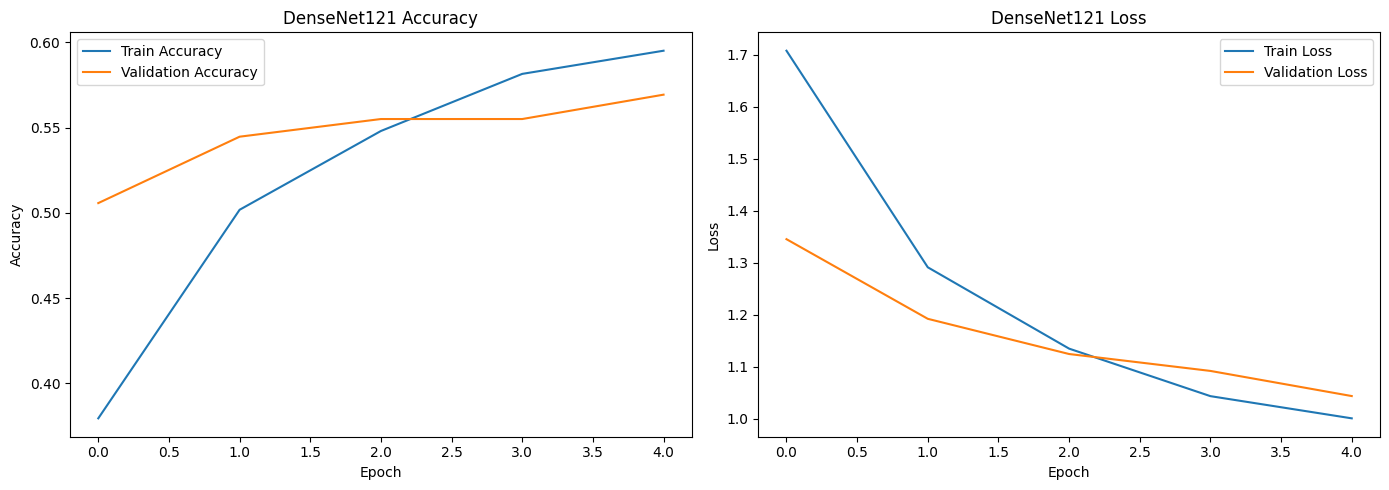

Training: InceptionV3
87910968/87910968 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/5
575/575 ━━━━━━━━━━━━━━━━━━━━ 0s 467ms/step - accuracy: 0.2926 - loss: 2.2566
Epoch 1: saving model to models/InceptionV3_best.keras

Epoch 1: finished saving model to models/InceptionV3_best.keras
575/575 ━━━━━━━━━━━━━━━━━━━━ 314s 514ms/step - accuracy: 0.3416 - loss: 2.0186 - val_accuracy: 0.4796 - val_loss: 1.2946 - learning_rate: 1.0000e-04
Epoch 2/5
575/575 ━━━━━━━━━━━━━━━━━━━━ 0s 468ms/step - accuracy: 0.4025 - loss: 1.7126
Epoch 2: saving model to models/InceptionV3_best.keras

Epoch 2: finished saving model to models/InceptionV3_best.keras
575/575 ━━━━━━━━━━━━━━━━━━━━ 282s 490ms/step - accuracy: 0.4097 - loss: 1.6745 - val_accuracy: 0.5293 - val_loss: 1.1686 - learning_rate: 1.0000e-04
Epoch 3/5
575/575 ━━━━━━━━━━━━━━━━━━━━ 0s 468ms/step - accuracy: 0.4456 - loss: 1.5545
Epoch 3: saving model to models/InceptionV3_best.keras

Epoch 3: finished saving model to models/InceptionV3_best.keras
575/575 

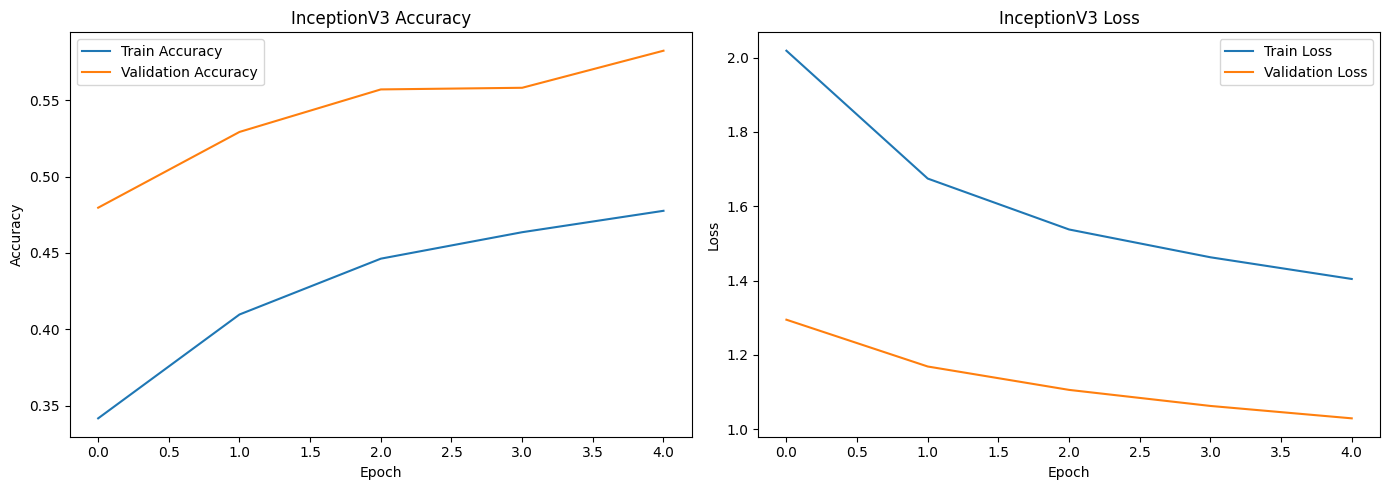

In [20]:
for model_name, config in MODEL_CONFIGS.items():

    model, history = train_model(
        model_name,
        config["model"]
    )

    models[model_name] = model
    histories[model_name] = history

    plot_training_history(
        history,
        model_name
    )

    # Memory clean
    gc.collect()

# **Test Prediction Function**

In [21]:
def get_predictions(model):

    test_generator.reset()

    probabilities = model.predict(
        test_generator,
        verbose=1
    )

    predictions = np.argmax(
        probabilities,
        axis=1
    )

    true_labels = test_generator.classes

    return true_labels, predictions, probabilities

# **Accuracy, Precision, Recall, F1**

In [22]:
def evaluate_model(model, model_name):

    # Get predictions
    y_true, y_pred, probabilities = get_predictions(model)

    # Metrics
    accuracy = accuracy_score(
        y_true,
        y_pred
    )

    precision = precision_score(
        y_true,
        y_pred,
        average="weighted",
        zero_division=0
    )

    recall = recall_score(
        y_true,
        y_pred,
        average="weighted",
        zero_division=0
    )

    f1 = f1_score(
        y_true,
        y_pred,
        average="weighted",
        zero_division=0
    )

    print(f"\n{'='*60}")
    print(f"{model_name}")
    print(f"{'='*60}")

    print(f"Accuracy  : {accuracy:.4f}")
    print(f"Precision : {precision:.4f}")
    print(f"Recall    : {recall:.4f}")
    print(f"F1 Score  : {f1:.4f}")

    # Classification Report
    print("\nClassification Report:\n")

    print(
        classification_report(
            y_true,
            y_pred,
            target_names=list(test_generator.class_indices.keys()),
            zero_division=0
        )
    )

    # Confusion Matrix
    cm = confusion_matrix(
        y_true,
        y_pred
    )

    plt.figure(figsize=(7, 6))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=test_generator.class_indices.keys(),
        yticklabels=test_generator.class_indices.keys()
    )

    plt.title(f"Confusion Matrix - {model_name}")
    plt.xlabel("Predicted Label")
    plt.ylabel("True Label")
    plt.tight_layout()
    plt.show()

    return {
        "Model": model_name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    }

# **Total Model Evaluate**

88/88 ━━━━━━━━━━━━━━━━━━━━ 213s 2s/step

Xception
Accuracy  : 0.4904
Precision : 0.4914
Recall    : 0.4904
F1 Score  : 0.4862

Classification Report:

              precision    recall  f1-score   support

          DR       0.46      0.48      0.47       350
         AMD       0.99      0.98      0.98       350
         CSR       0.50      0.59      0.54       350
      DRUSEN       0.34      0.24      0.28       350
         CNV       0.48      0.37      0.41       350
      NORMAL       0.37      0.53      0.44       350
          MH       0.45      0.40      0.42       350
         DME       0.34      0.34      0.34       350

    accuracy                           0.49      2800
   macro avg       0.49      0.49      0.49      2800
weighted avg       0.49      0.49      0.49      2800



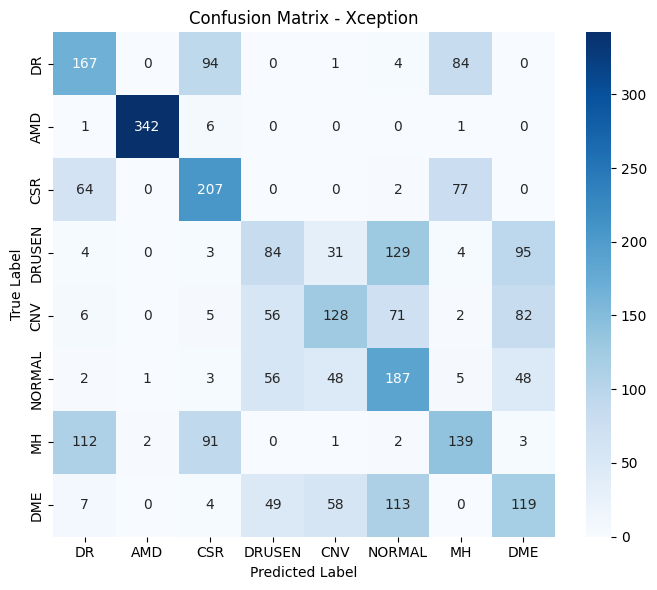

88/88 ━━━━━━━━━━━━━━━━━━━━ 19s 168ms/step

ResNet50
Accuracy  : 0.8204
Precision : 0.8246
Recall    : 0.8204
F1 Score  : 0.8190

Classification Report:

              precision    recall  f1-score   support

          DR       0.91      0.79      0.85       350
         AMD       1.00      0.97      0.98       350
         CSR       0.84      1.00      0.91       350
      DRUSEN       0.69      0.60      0.64       350
         CNV       0.70      0.80      0.75       350
      NORMAL       0.72      0.84      0.77       350
          MH       0.95      0.89      0.91       350
         DME       0.79      0.68      0.73       350

    accuracy                           0.82      2800
   macro avg       0.82      0.82      0.82      2800
weighted avg       0.82      0.82      0.82      2800



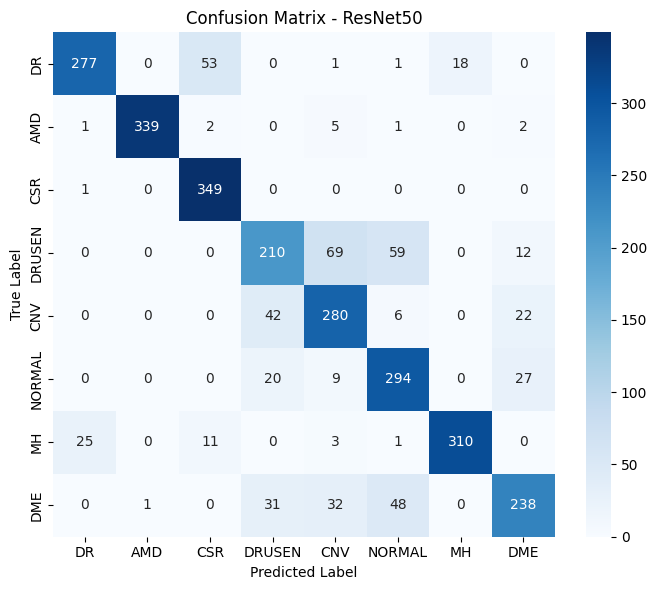

88/88 ━━━━━━━━━━━━━━━━━━━━ 21s 181ms/step

MobileNetV3Large
Accuracy  : 0.8064
Precision : 0.8192
Recall    : 0.8064
F1 Score  : 0.8068

Classification Report:

              precision    recall  f1-score   support

          DR       0.85      0.85      0.85       350
         AMD       0.99      0.97      0.98       350
         CSR       0.88      0.91      0.90       350
      DRUSEN       0.59      0.77      0.66       350
         CNV       0.83      0.61      0.70       350
      NORMAL       0.69      0.83      0.76       350
          MH       0.92      0.88      0.90       350
         DME       0.81      0.63      0.71       350

    accuracy                           0.81      2800
   macro avg       0.82      0.81      0.81      2800
weighted avg       0.82      0.81      0.81      2800



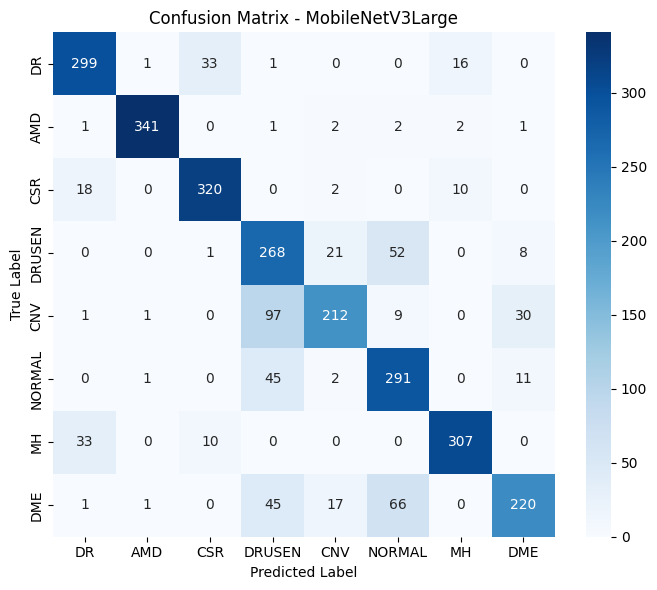

88/88 ━━━━━━━━━━━━━━━━━━━━ 61s 484ms/step

EfficientNetB7
Accuracy  : 0.8396
Precision : 0.8432
Recall    : 0.8396
F1 Score  : 0.8384

Classification Report:

              precision    recall  f1-score   support

          DR       0.92      0.83      0.87       350
         AMD       0.94      0.96      0.95       350
         CSR       0.88      0.96      0.92       350
      DRUSEN       0.77      0.67      0.72       350
         CNV       0.76      0.75      0.75       350
      NORMAL       0.72      0.93      0.81       350
          MH       0.96      0.92      0.94       350
         DME       0.79      0.71      0.75       350

    accuracy                           0.84      2800
   macro avg       0.84      0.84      0.84      2800
weighted avg       0.84      0.84      0.84      2800



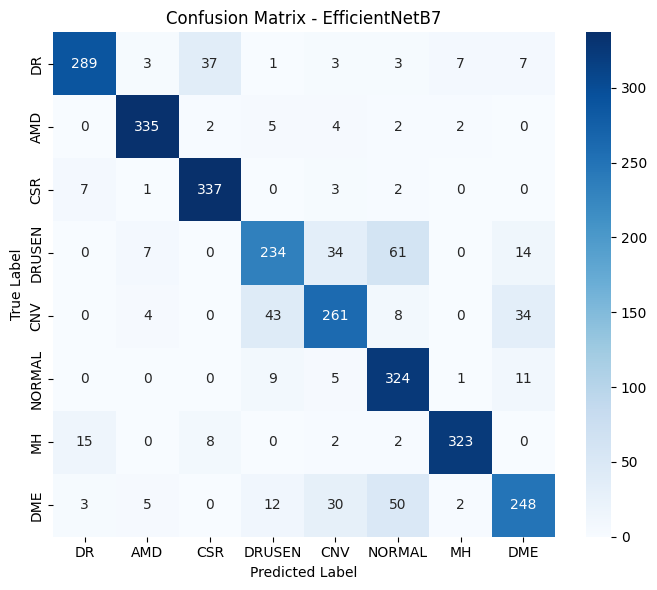

88/88 ━━━━━━━━━━━━━━━━━━━━ 36s 272ms/step

DenseNet121
Accuracy  : 0.5554
Precision : 0.6120
Recall    : 0.5554
F1 Score  : 0.5350

Classification Report:

              precision    recall  f1-score   support

          DR       0.71      0.49      0.58       350
         AMD       0.99      0.99      0.99       350
         CSR       0.50      0.94      0.65       350
      DRUSEN       0.32      0.54      0.40       350
         CNV       0.61      0.49      0.54       350
      NORMAL       0.53      0.64      0.58       350
          MH       0.92      0.19      0.32       350
         DME       0.32      0.17      0.22       350

    accuracy                           0.56      2800
   macro avg       0.61      0.56      0.54      2800
weighted avg       0.61      0.56      0.54      2800



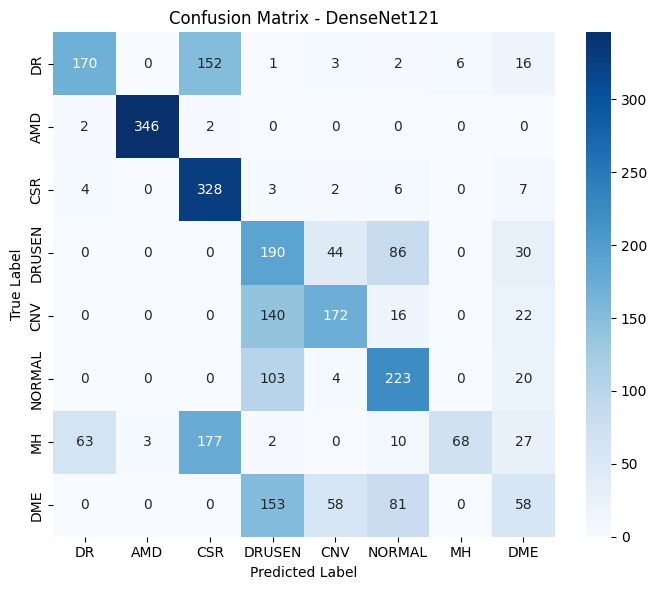

88/88 ━━━━━━━━━━━━━━━━━━━━ 24s 194ms/step

InceptionV3
Accuracy  : 0.5875
Precision : 0.5938
Recall    : 0.5875
F1 Score  : 0.5863

Classification Report:

              precision    recall  f1-score   support

          DR       0.62      0.55      0.58       350
         AMD       0.99      0.96      0.98       350
         CSR       0.62      0.75      0.68       350
      DRUSEN       0.40      0.39      0.39       350
         CNV       0.53      0.58      0.55       350
      NORMAL       0.50      0.59      0.54       350
          MH       0.64      0.43      0.51       350
         DME       0.46      0.46      0.46       350

    accuracy                           0.59      2800
   macro avg       0.59      0.59      0.59      2800
weighted avg       0.59      0.59      0.59      2800



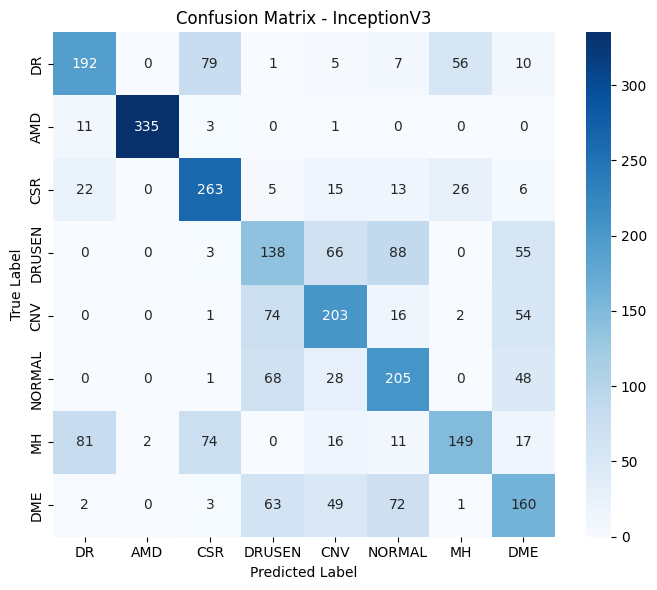

,Model,Accuracy,Precision,Recall,F1 Score
0,Xception,0.490357,0.491424,0.490357,0.486222
1,ResNet50,0.820357,0.824615,0.820357,0.819036
2,MobileNetV3Large,0.806429,0.819150,0.806429,0.806753
3,EfficientNetB7,0.839643,0.843168,0.839643,0.838382
4,DenseNet121,0.555357,0.612029,0.555357,0.535009
5,InceptionV3,0.587500,0.593785,0.587500,0.586252


In [23]:
results = []

for model_name, model in models.items():

    result = evaluate_model(
        model,
        model_name
    )

    results.append(result)

results_df = pd.DataFrame(results)

results_df

# **Accuracy Comparison**

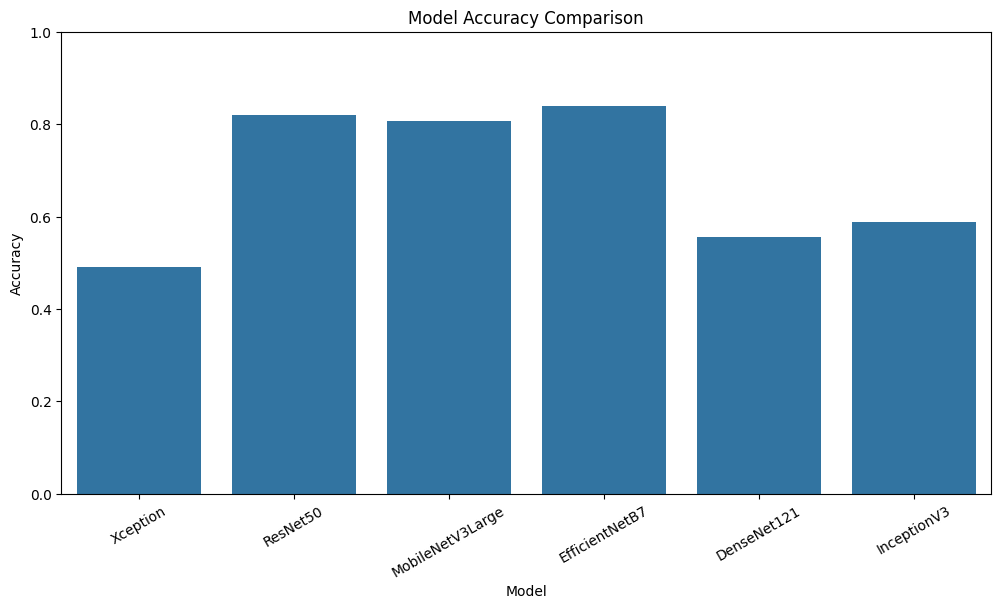

In [24]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=results_df,
    x="Model",
    y="Accuracy"
)

plt.ylim(0, 1)

plt.title("Model Accuracy Comparison")

plt.xticks(rotation=30)

plt.show()

# **Precision Comparison**

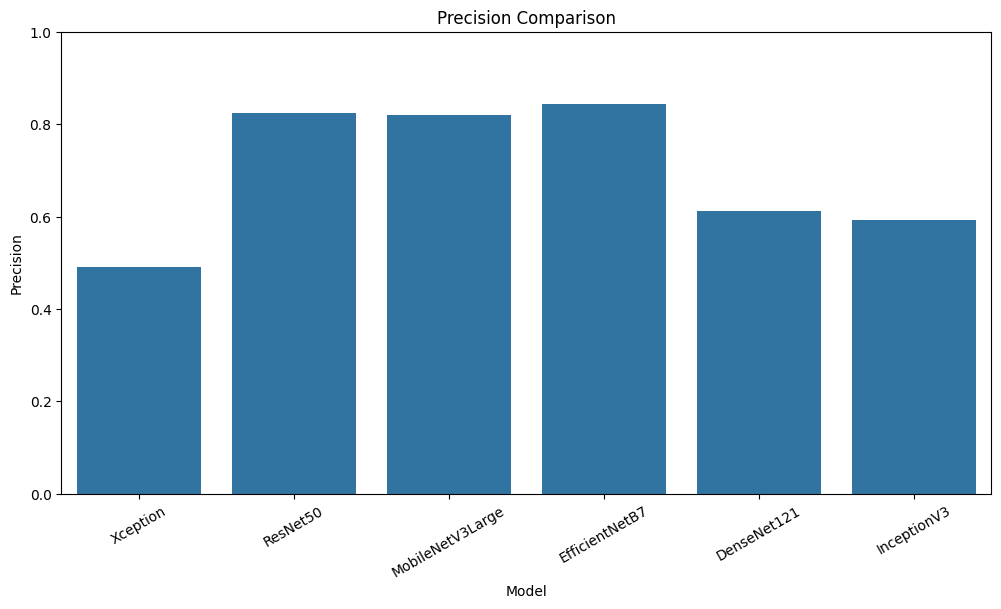

In [25]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=results_df,
    x="Model",
    y="Precision"
)

plt.ylim(0, 1)

plt.title("Precision Comparison")

plt.xticks(rotation=30)

plt.show()

# **Recall Comparison**

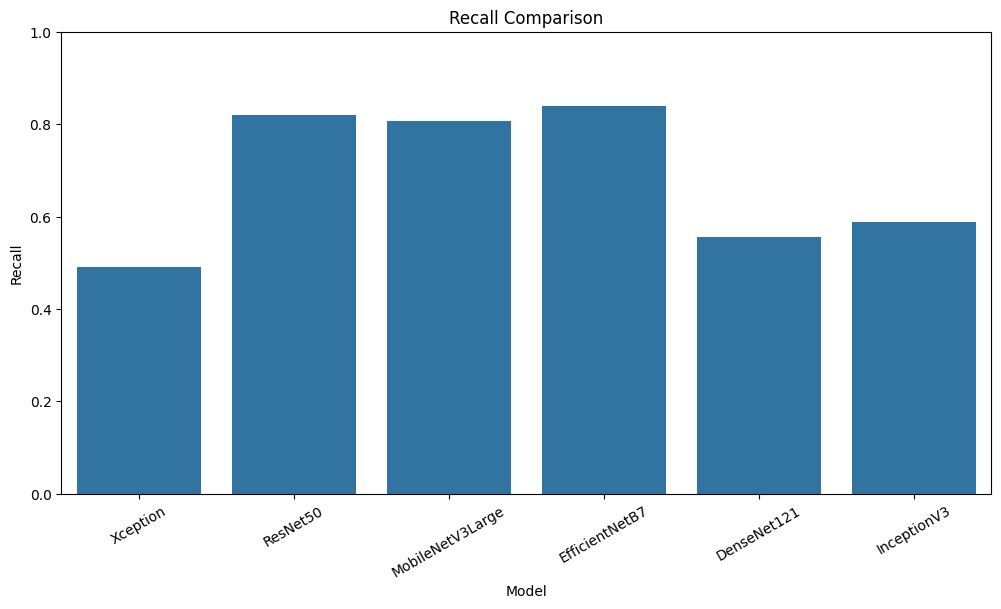

In [26]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=results_df,
    x="Model",
    y="Recall"
)

plt.ylim(0, 1)

plt.title("Recall Comparison")

plt.xticks(rotation=30)

plt.show()

# **F1-Score Comparison**

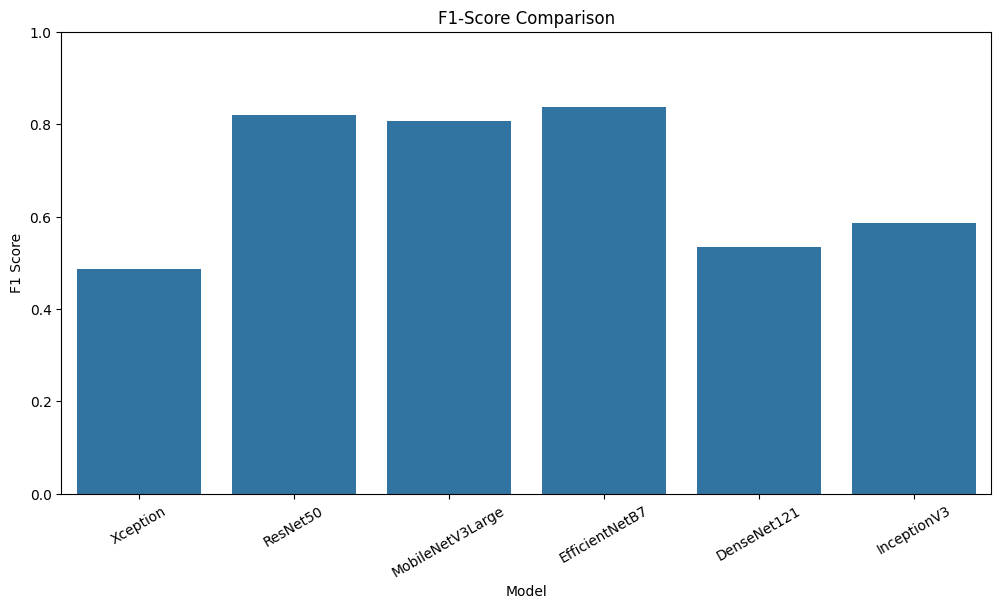

In [27]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=results_df,
    x="Model",
    y="F1 Score"
)

plt.ylim(0, 1)

plt.title("F1-Score Comparison")

plt.xticks(rotation=30)

plt.show()

# **Total Metrics**

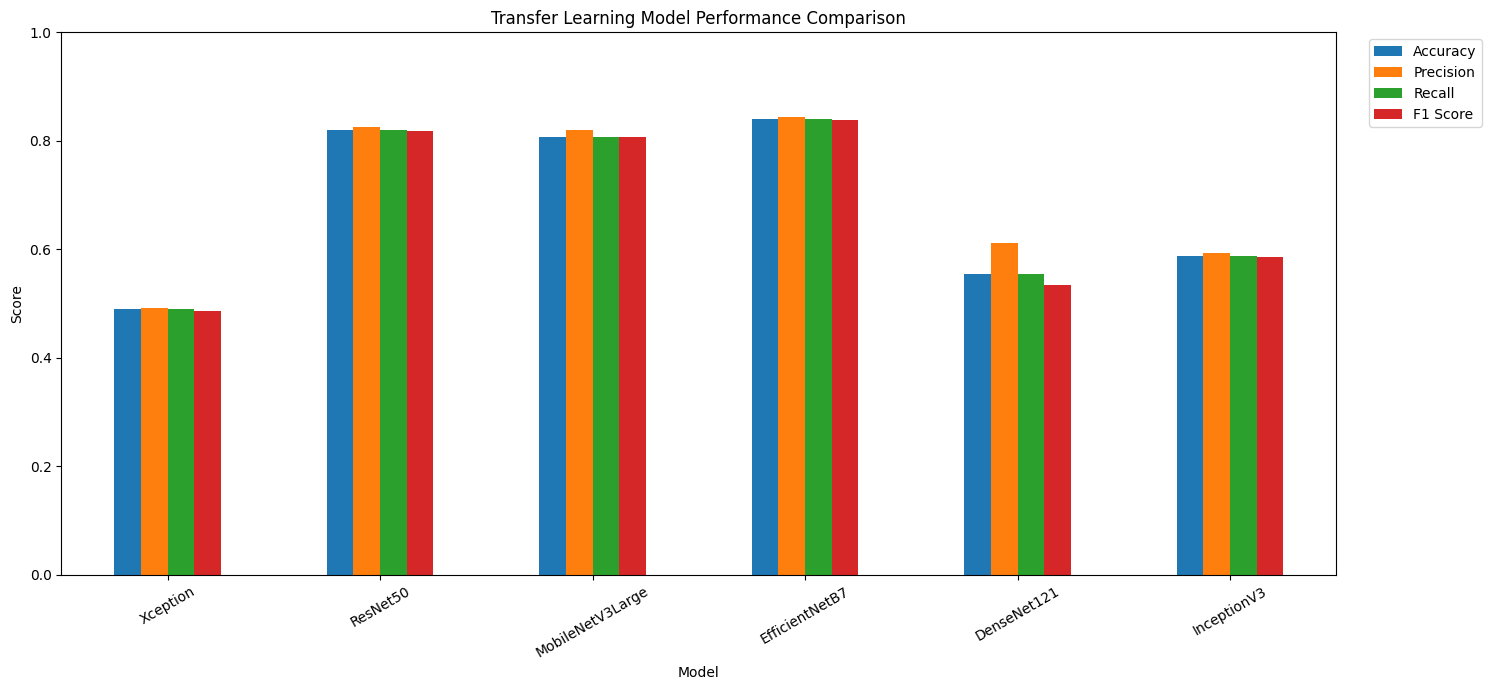

In [28]:
metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score"
]

results_plot = results_df.set_index("Model")[metrics]

results_plot.plot(
    kind="bar",
    figsize=(15, 7)
)

plt.ylim(0, 1)

plt.title(
    "Transfer Learning Model Performance Comparison"
)

plt.ylabel("Score")

plt.xticks(rotation=30)

plt.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()

plt.show()

# **Confusion Matrix**

In [29]:
def plot_confusion_matrix(model, model_name):

    y_true, y_pred, _ = get_predictions(model)

    cm = confusion_matrix(
        y_true,
        y_pred
    )

    plt.figure(figsize=(6, 5))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=CLASS_NAMES,
        yticklabels=CLASS_NAMES
    )

    plt.xlabel("Predicted")
    plt.ylabel("Actual")

    plt.title(
        f"{model_name} - Confusion Matrix"
    )

    plt.show()

88/88 ━━━━━━━━━━━━━━━━━━━━ 12s 140ms/step


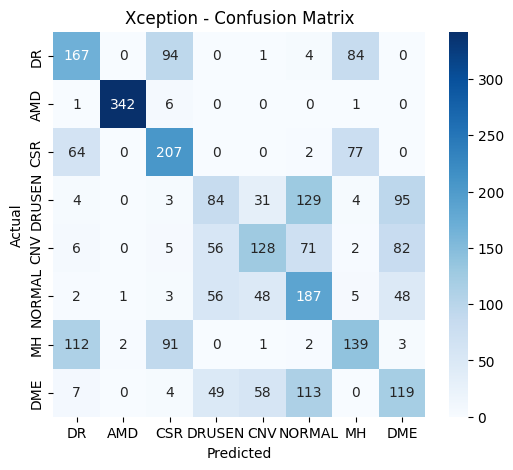

88/88 ━━━━━━━━━━━━━━━━━━━━ 11s 121ms/step


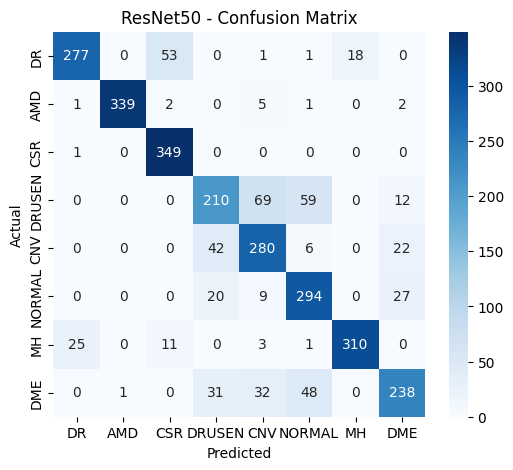

88/88 ━━━━━━━━━━━━━━━━━━━━ 11s 124ms/step


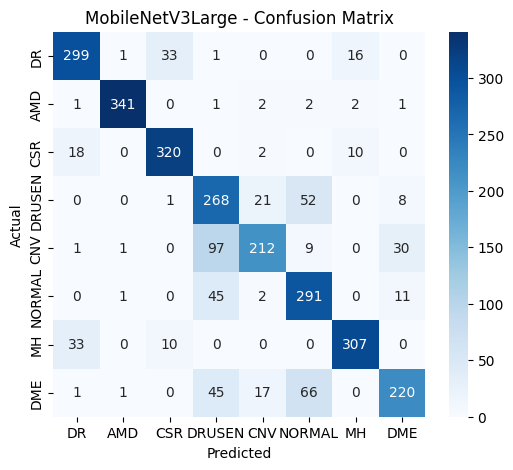

88/88 ━━━━━━━━━━━━━━━━━━━━ 22s 252ms/step


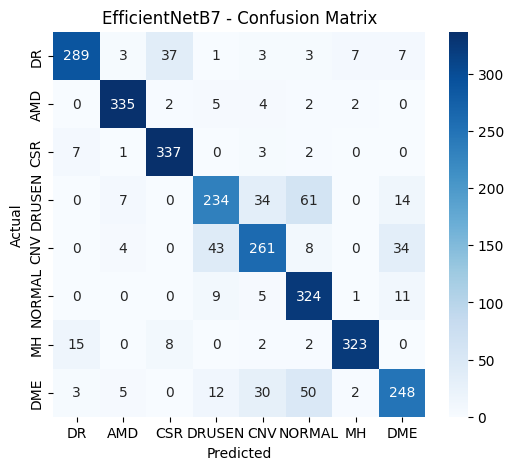

88/88 ━━━━━━━━━━━━━━━━━━━━ 12s 129ms/step


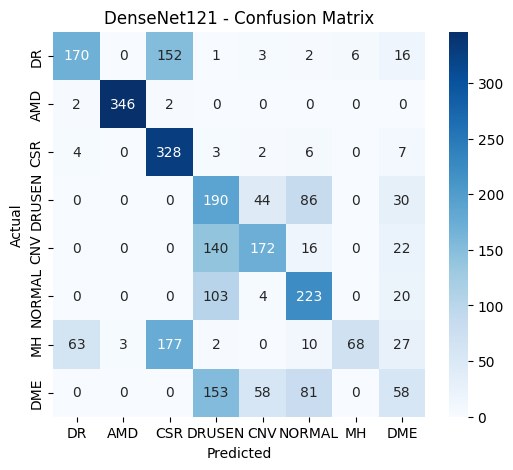

88/88 ━━━━━━━━━━━━━━━━━━━━ 11s 121ms/step


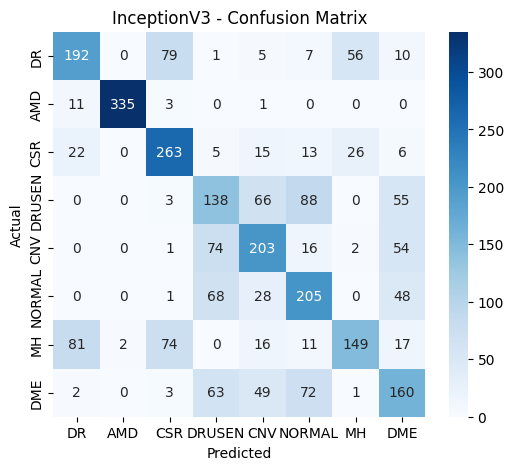

In [30]:
for model_name, model in models.items():

    plot_confusion_matrix(
        model,
        model_name
    )

# **Classification Report**

In [31]:
for model_name, model in models.items():

    y_true, y_pred, _ = get_predictions(model)

    print("\n")
    print("=" * 70)
    print(model_name)
    print("=" * 70)

    print(
        classification_report(
            y_true,
            y_pred,
            target_names=CLASS_NAMES,
            digits=4
        )
    )

88/88 ━━━━━━━━━━━━━━━━━━━━ 12s 133ms/step


Xception
              precision    recall  f1-score   support

          DR     0.4601    0.4771    0.4684       350
         AMD     0.9913    0.9771    0.9842       350
         CSR     0.5012    0.5914    0.5426       350
      DRUSEN     0.3429    0.2400    0.2824       350
         CNV     0.4794    0.3657    0.4149       350
      NORMAL     0.3681    0.5343    0.4359       350
          MH     0.4455    0.3971    0.4199       350
         DME     0.3429    0.3400    0.3415       350

    accuracy                         0.4904      2800
   macro avg     0.4914    0.4904    0.4862      2800
weighted avg     0.4914    0.4904    0.4862      2800

88/88 ━━━━━━━━━━━━━━━━━━━━ 11s 128ms/step


ResNet50
              precision    recall  f1-score   support

          DR     0.9112    0.7914    0.8471       350
         AMD     0.9971    0.9686    0.9826       350
         CSR     0.8410    0.9971    0.9124       350
      DRUSEN     0.6931   

# **ROC Curve**

88/88 ━━━━━━━━━━━━━━━━━━━━ 12s 135ms/step


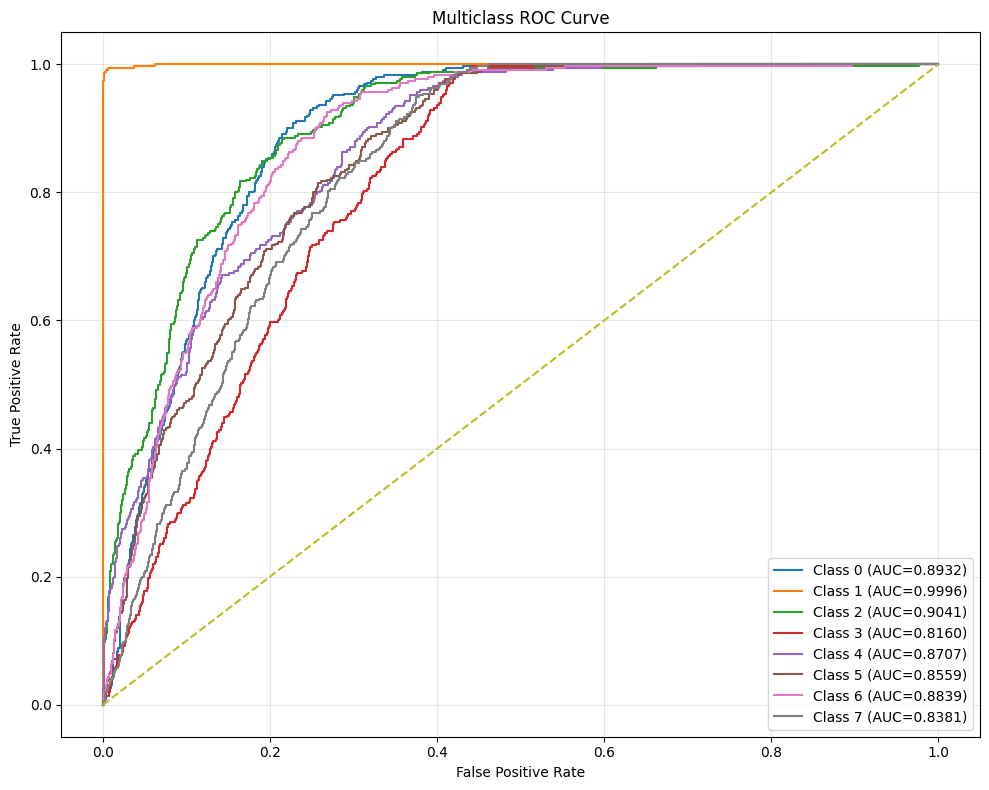

In [32]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, roc_auc_score

n_classes = len(test_generator.class_indices)

y_true, y_pred, y_prob = get_predictions(
    list(models.values())[0]
)

y_true_bin = label_binarize(
    y_true,
    classes=np.arange(n_classes)
)

plt.figure(figsize=(10, 8))

for class_id in range(n_classes):

    fpr, tpr, _ = roc_curve(
        y_true_bin[:, class_id],
        y_prob[:, class_id]
    )

    auc_score = roc_auc_score(
        y_true_bin[:, class_id],
        y_prob[:, class_id]
    )

    plt.plot(
        fpr,
        tpr,
        label=f"Class {class_id} (AUC={auc_score:.4f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Multiclass ROC Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# **Heatmap — Model vs Metrics**

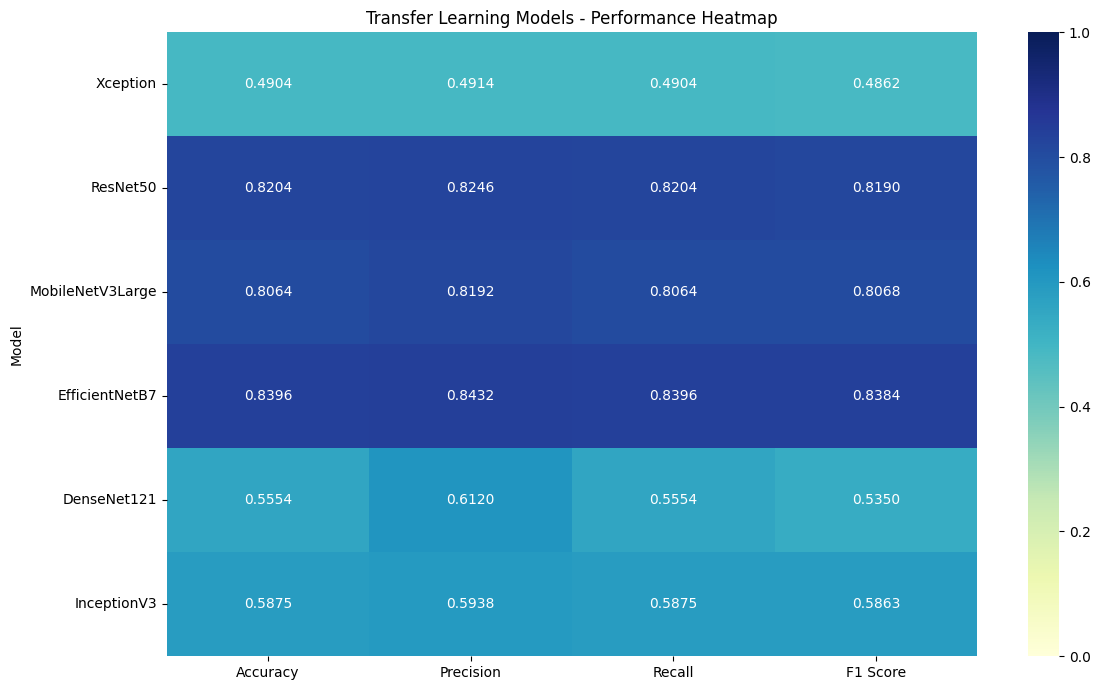

In [33]:
heatmap_data = results_df.set_index(
    "Model"
)[
    [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
    ]
]

plt.figure(figsize=(12, 7))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".4f",
    cmap="YlGnBu",
    vmin=0,
    vmax=1
)

plt.title(
    "Transfer Learning Models - Performance Heatmap"
)

plt.tight_layout()

plt.show()

# **Find Best Model**

In [34]:
print("Highest Accuracy:")
print(
    results_df.loc[
        results_df["Accuracy"].idxmax()
    ]
)

print("\nHighest Precision:")
print(
    results_df.loc[
        results_df["Precision"].idxmax()
    ]
)

print("\nHighest Recall:")
print(
    results_df.loc[
        results_df["Recall"].idxmax()
    ]
)

print("\nHighest F1:")
print(
    results_df.loc[
        results_df["F1 Score"].idxmax()
    ]
)


Highest Accuracy:
Model        EfficientNetB7
Accuracy           0.839643
Precision          0.843168
Recall             0.839643
F1 Score           0.838382
Name: 3, dtype: object

Highest Precision:
Model        EfficientNetB7
Accuracy           0.839643
Precision          0.843168
Recall             0.839643
F1 Score           0.838382
Name: 3, dtype: object

Highest Recall:
Model        EfficientNetB7
Accuracy           0.839643
Precision          0.843168
Recall             0.839643
F1 Score           0.838382
Name: 3, dtype: object

Highest F1:
Model        EfficientNetB7
Accuracy           0.839643
Precision          0.843168
Recall             0.839643
F1 Score           0.838382
Name: 3, dtype: object


# **Overall Comparison**

In [35]:
results_df.sort_values(
    by="F1 Score",
    ascending=False
)

,Model,Accuracy,Precision,Recall,F1 Score
3,EfficientNetB7,0.839643,0.843168,0.839643,0.838382
1,ResNet50,0.820357,0.824615,0.820357,0.819036
2,MobileNetV3Large,0.806429,0.819150,0.806429,0.806753
5,InceptionV3,0.587500,0.593785,0.587500,0.586252
4,DenseNet121,0.555357,0.612029,0.555357,0.535009
0,Xception,0.490357,0.491424,0.490357,0.486222


# **Fine-Tuning — 2nd Stage**

Stage-1 Transfer Learning।

In [36]:
def prepare_fine_tuning(model, unfreeze_from=-30):

    base_model = None

    for layer in model.layers:

        if hasattr(layer, "layers"):

            if "conv" in layer.name.lower() or \
               "efficient" in layer.name.lower() or \
               "resnet" in layer.name.lower() or \
               "xception" in layer.name.lower() or \
               "densenet" in layer.name.lower():

                base_model = layer

    if base_model is None:
        print("Base model not found.")
        return model

    base_model.trainable = True

    for layer in base_model.layers[:unfreeze_from]:
        layer.trainable = False

    for layer in base_model.layers[unfreeze_from:]:
        layer.trainable = True

    model.compile(
        optimizer=keras.optimizers.Adamax(
            learning_rate=1e-5
        ),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model

In [37]:
fine_tuned_model = prepare_fine_tuning(
    models["Xception"],
    unfreeze_from=-30
)

In [38]:
history_ft = fine_tuned_model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=10,
    callbacks=get_callbacks("Xception_FineTuned")
)

Epoch 1/10


2026-11-25 16:33:22.573507: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-25 16:33:22.712846: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


575/575 ━━━━━━━━━━━━━━━━━━━━ 0s 486ms/step - accuracy: 0.2955 - loss: 1.9100
Epoch 1: saving model to models/Xception_FineTuned_best.keras

Epoch 1: finished saving model to models/Xception_FineTuned_best.keras
575/575 ━━━━━━━━━━━━━━━━━━━━ 323s 525ms/step - accuracy: 0.3357 - loss: 1.7297 - val_accuracy: 0.4139 - val_loss: 1.3343 - learning_rate: 1.0000e-05
Epoch 2/10
575/575 ━━━━━━━━━━━━━━━━━━━━ 0s 480ms/step - accuracy: 0.3856 - loss: 1.5066
Epoch 2: saving model to models/Xception_FineTuned_best.keras

Epoch 2: finished saving model to models/Xception_FineTuned_best.keras
575/575 ━━━━━━━━━━━━━━━━━━━━ 290s 503ms/step - accuracy: 0.3899 - loss: 1.4776 - val_accuracy: 0.4468 - val_loss: 1.2267 - learning_rate: 1.0000e-05
Epoch 3/10
575/575 ━━━━━━━━━━━━━━━━━━━━ 0s 483ms/step - accuracy: 0.4091 - loss: 1.4124
Epoch 3: saving model to models/Xception_FineTuned_best.keras

Epoch 3: finished saving model to models/Xception_FineTuned_best.keras
575/575 ━━━━━━━━━━━━━━━━━━━━ 291s 506ms/step - 